In [1]:
import jax.numpy as jnp
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import numpyro
import numpyro.distributions as dist
from numpyro.handlers import seed

In [2]:
sns.set_theme(style="whitegrid")

## Generating members table

In [7]:
N_members = 500
with seed(rng_seed=17):
    age_offset = numpyro.sample("age_offset", dist.Gamma(concentration=3.0, rate=0.22).expand((N_members,)))
    age = jnp.clip(jnp.round(18 + age_offset), 18.0, 70.0)

    distance_km = numpyro.sample("distance_km", dist.LogNormal(loc=0.8, scale=0.65).expand((N_members,)))
    distance_km = jnp.round(jnp.clip(distance_km, 0.2, 25.0), 2)

    promo_friends = numpyro.sample("promo_friends", dist.Bernoulli(probs=0.30).expand((N_members,)))

    partners_company = numpyro.sample("partners_company", dist.Bernoulli(probs=0.25).expand((N_members,)))

    # Hidden simulator feature
    attends_groups = numpyro.sample("attends_groups", dist.Bernoulli(probs=0.35).expand((N_members, )))
    group_prop_if_active = numpyro.sample("group_prop_raw", dist.Beta(concentration1=2.5, concentration0=2.0).expand((N_members, )))
    true_group_prop = attends_groups * group_prop_if_active

members_df = pd.DataFrame({
    "member_id": np.arange(1, N_members+1),
    "age": np.asarray(age, dtype=int),
    "distance_km": np.asarray(distance_km),
    "promo_friends": np.asarray(promo_friends, dtype=int),
    "partners_company": np.asarray(partners_company, dtype=int),
    "_true_group_prop": np.round(np.asarray(true_group_prop), 3),
})
members_df.head(10)

,member_id,age,distance_km,promo_friends,partners_company,_true_group_prop
0,1,32,3.39,0,0,0.000
1,2,37,4.21,0,1,0.000
2,3,23,4.31,1,0,0.000
3,4,45,2.29,0,1,0.000
4,5,29,1.11,0,0,0.690
5,6,24,0.89,0,0,0.000
6,7,42,0.65,1,0,0.409
7,8,28,2.21,1,0,0.000
8,9,26,1.72,1,1,0.000
9,10,32,3.87,0,0,0.000


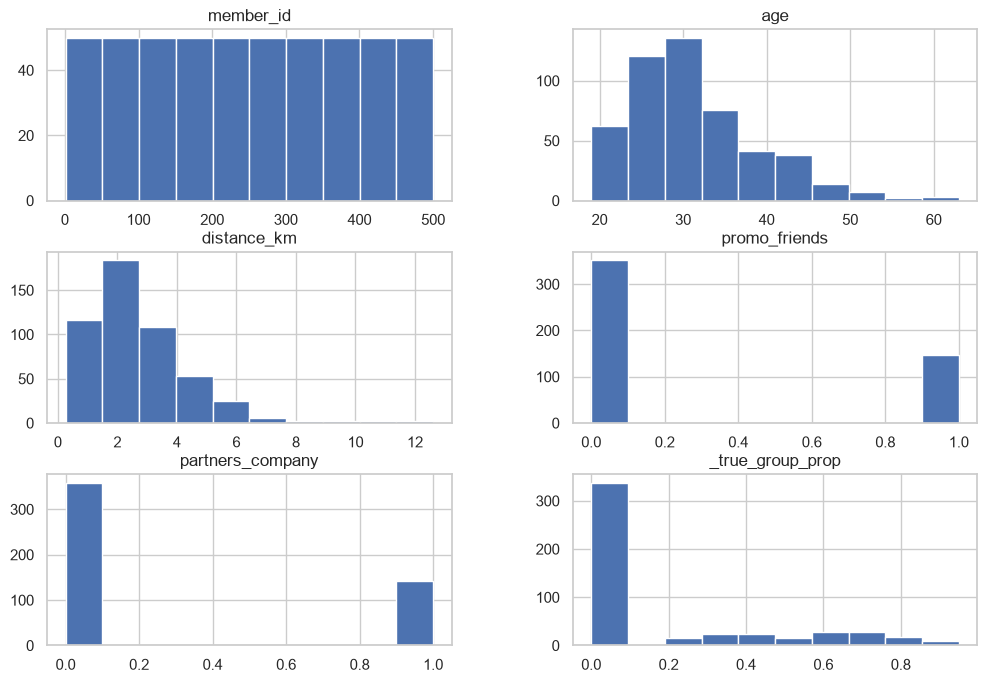

In [9]:
members_df.hist(figsize=(12, 8))
plt.show()

## Generating contracts table

In [14]:
age_z = jnp.asarray((members_df["age"] - members_df["age"].mean()) / members_df["age"].std())
dist_z = jnp.asarray((members_df["distance_km"] - members_df["distance_km"].mean()) / members_df["distance_km"].std())

promo_f = jnp.asarray(members_df["promo_friends"])
partner_c = jnp.asarray(members_df["partners_company"])
group_p = jnp.asarray(members_df["_true_group_prop"])

N_current = len(members_df)

In [15]:
TRUE_PARAMS = {
    "mu_lambda": jnp.log(2.6),
    "beta_lambda_dist": -0.12,
    "beta_lambda_group": 0.25,
    "sigma_lambda": 0.30,

    "mu_tau": jnp.log(16.0),
    "beta_tau_dist": -0.35,
    "beta_tau_friends": 0.45,
    "beta_tau_group": 0.70,
    "beta_tau_partner": 0.20,
    "beta_tau_age": 0.12,
    "sigma_tau": 0.45,

    "mu_gamma": jnp.log(0.35),
    "beta_gamma_group": -0.45,
    "beta_gamma_friends": -0.25,
    "sigma_gamma": 0.45,
}

In [16]:
with seed(rng_seed=101):
    z_lambda = numpyro.sample("z_lambda", dist.Normal(0, 1).expand((N_current,)))
    z_tau = numpyro.sample("z_tau", dist.Normal(0, 1).expand((N_current,)))
    z_gamma = numpyro.sample("z_gamma", dist.Normal(0, 1).expand((N_current,)))

    log_lambda_base = (
        TRUE_PARAMS["mu_lambda"]
        + TRUE_PARAMS["beta_lambda_dist"] * dist_z
        + TRUE_PARAMS["beta_lambda_group"] * group_p
        + TRUE_PARAMS["sigma_lambda"] * z_lambda
    )

    log_tau = (
        TRUE_PARAMS["mu_tau"]
        + TRUE_PARAMS["beta_tau_dist"] * dist_z
        + TRUE_PARAMS["beta_tau_friends"] * promo_f
        + TRUE_PARAMS["beta_tau_group"] * group_p
        + TRUE_PARAMS["beta_tau_partner"] * partner_c
        + TRUE_PARAMS["beta_tau_age"] * age_z
        + TRUE_PARAMS["sigma_tau"] * z_tau
    )

    log_gamma = (
        TRUE_PARAMS["mu_gamma"]
        + TRUE_PARAMS["beta_gamma_group"] * group_p
        + TRUE_PARAMS["beta_gamma_friends"] * promo_f
        + TRUE_PARAMS["sigma_gamma"] * z_gamma
    )

    true_lambda_base = jnp.exp(log_lambda_base)
    true_tau = jnp.exp(log_tau)
    true_gamma = jnp.exp(log_gamma)

# Dopisujemy ukryte parametry prawdy do tabeli (z prefiksem '_')
members_df["_true_lambda_base"] = np.round(np.asarray(true_lambda_base), 2)
members_df["_true_tau"] = np.round(np.asarray(true_tau), 1)
members_df["_true_gamma"] = np.round(np.asarray(true_gamma), 3)

members_df[["member_id", "distance_km", "promo_friends", "_true_group_prop", "_true_lambda_base", "_true_tau", "_true_gamma"]].head(10)

,member_id,distance_km,promo_friends,_true_group_prop,_true_lambda_base,_true_tau,_true_gamma
0,1,3.39,0,0.000,2.06,26.299999,0.633
1,2,4.21,0,0.000,3.71,11.300000,0.509
2,3,4.31,1,0.000,2.31,18.299999,0.212
3,4,2.29,0,0.000,2.88,32.099998,0.478
4,5,1.11,0,0.690,2.60,39.500000,0.316
5,6,0.89,0,0.000,3.38,44.400002,0.813
6,7,0.65,1,0.409,3.24,45.200001,0.220
7,8,2.21,1,0.000,2.86,27.700001,0.353
8,9,1.72,1,0.000,4.37,33.099998,0.361
9,10,3.87,0,0.000,3.00,17.799999,0.496


In [21]:
from datetime import datetime, timedelta

rng = np.random.default_rng(seed=2026)

START_DATE = datetime(2024, 1, 1)
TOTAL_WEEKS = 104
VACATION_PROB = 0.06

TRUE_CHURN_PARAMS = {
    "intercept": 0.8,
    "beta_current_lambda": -1.6,
    "beta_habit_drop": 1.8,
    "beta_end_shock": 0.9,
}

contracts_list = []
check_ins_list = []
contract_id_counter = 1

for _, member in members_df.iterrows():
    m_id = int(member["member_id"])
    current_week = int(rng.integers(0, 75))

    lam_base = float(member["_true_lambda_base"])
    tau = float(member["_true_tau"])
    gamma = float(member["_true_gamma"])
    group_prop = float(member["_true_group_prop"])
    has_partner_discount = int(member["partners_company"]) == 1

    for episode_num in [1, 2]:
        if current_week >= TOTAL_WEEKS:
            break

        if episode_num == 2:
            tau = float(tau * rng.uniform(0.7, 1.3))

        t_in_episode = 0
        episode_active = True
        c_months = int(rng.choice([1, 6, 12], p=[0.50, 0.20, 0.30]))

        while episode_active and current_week < TOTAL_WEEKS:
            current_c_months = c_months
            c_weeks = current_c_months * 4
            c_start_week = current_week
            c_end_week = c_start_week + c_weeks

            base_price = {1: 199.0, 6: 169.0, 12: 139.0}[current_c_months]
            monthly_price = round(base_price * (0.85 if has_partner_discount else 1.0), 2)

            last_simulated_week = min(c_end_week, TOTAL_WEEKS)
            for w in range(c_start_week, last_simulated_week):
                t_in_episode += 1
                lam_t = lam_base / (1.0 + np.exp(gamma * (t_in_episode - tau)))

                is_vacation = rng.random() < VACATION_PROB
                n_visits = 0 if is_vacation else int(rng.poisson(lam_t))

                for v in range(n_visits):
                    day_offset = int(rng.integers(0, 7))
                    hour_offset = int(rng.integers(7, 21))
                    minute_offset = int(rng.integers(0, 60))
                    checkin_time = START_DATE + timedelta(
                        weeks=int(w), days=day_offset, hours=hour_offset, minutes=minute_offset
                    )

                    is_group = int(rng.random() < group_prop)
                    spend = round(float(rng.exponential(15.0)), 2) if rng.random() < 0.25 else 0.0

                    check_ins_list.append({
                        "member_id": m_id,
                        "timestamp": checkin_time,
                        "is_group_class": is_group,
                        "additional_spend": spend,
                    })

                    if rng.random() < 0.02:
                        duplicate_time = checkin_time + timedelta(minutes=int(rng.integers(5, 40)))
                        check_ins_list.append({
                            "member_id": m_id,
                            "timestamp": duplicate_time,
                            "is_group_class": 0,
                            "additional_spend": 0.0,
                        })

            next_c_months = current_c_months
            slip_weeks = 0

            if c_end_week > TOTAL_WEEKS:
                status = "active"
                episode_active = False
            else:
                lam_at_end = lam_base / (1.0 + np.exp(gamma * (t_in_episode - tau)))
                habit_drop_ratio = 1.0 - (lam_at_end / max(lam_base, 0.01))
                is_long_contract_shock = 1.0 if current_c_months in [6, 12] else 0.0

                logit_churn = (
                    TRUE_CHURN_PARAMS["intercept"]
                    + TRUE_CHURN_PARAMS["beta_current_lambda"] * lam_at_end
                    + TRUE_CHURN_PARAMS["beta_habit_drop"] * habit_drop_ratio
                    + TRUE_CHURN_PARAMS["beta_end_shock"] * is_long_contract_shock
                )
                prob_churn = 1.0 / (1.0 + np.exp(-logit_churn))

                if rng.random() < prob_churn:
                    status = "churned"
                    episode_active = False
                else:
                    status = "renewed"
                    slip_weeks = int(rng.choice([0, 1], p=[0.8, 0.2]))
                    next_c_months = int(rng.choice([1, 6, 12], p=[0.70, 0.15, 0.15]))

            contracts_list.append({
                "contract_id": contract_id_counter,
                "member_id": m_id,
                "start_date": (START_DATE + timedelta(weeks=int(c_start_week))).strftime("%Y-%m-%d"),
                "end_date": (START_DATE + timedelta(weeks=int(c_end_week))).strftime("%Y-%m-%d"),
                "duration_months": current_c_months,
                "monthly_price": monthly_price,
                "status": status,
            })
            contract_id_counter += 1

            if status == "renewed":
                current_week = c_end_week + slip_weeks
                t_in_episode += slip_weeks
                c_months = next_c_months

        if episode_num == 1 and status == "churned":
            if rng.random() < 0.20:
                break_weeks = int(rng.integers(10, 25))
                current_week = c_end_week + break_weeks
            else:
                break
        else:
            break

contracts_df = pd.DataFrame(contracts_list)
check_ins_df = pd.DataFrame(check_ins_list).sort_values("timestamp").reset_index(drop=True)

display(contracts_df.head(10))

,contract_id,member_id,start_date,end_date,duration_months,monthly_price,status
0,1,1,2025-03-17,2025-09-01,6,169.00,renewed
1,2,1,2025-09-01,2025-09-29,1,199.00,churned
2,3,2,2024-12-09,2025-01-06,1,169.15,renewed
3,4,2,2025-01-06,2025-02-03,1,169.15,renewed
4,5,2,2025-02-10,2025-03-10,1,169.15,renewed
5,6,2,2025-03-10,2025-08-25,6,143.65,churned
6,7,3,2024-04-01,2025-03-03,12,139.00,churned
7,8,4,2025-04-21,2026-03-23,12,118.15,active
8,9,5,2024-08-05,2024-09-02,1,199.00,renewed
9,10,5,2024-09-09,2024-10-07,1,199.00,renewed


array([[<Axes: title={'center': 'contract_id'}>,
        <Axes: title={'center': 'member_id'}>],
       [<Axes: title={'center': 'duration_months'}>,
        <Axes: title={'center': 'monthly_price'}>]], dtype=object)

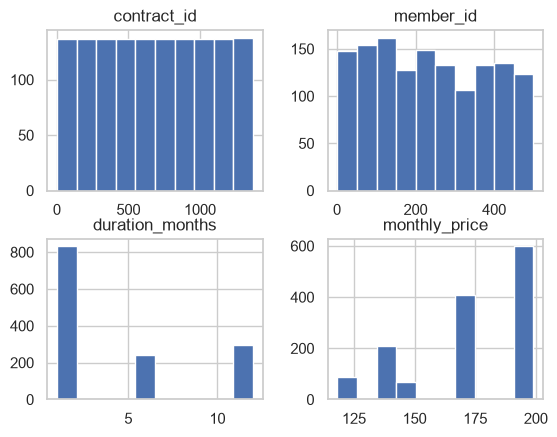

In [22]:
contracts_df.hist()

array([[<Axes: title={'center': 'member_id'}>,
        <Axes: title={'center': 'timestamp'}>],
       [<Axes: title={'center': 'is_group_class'}>,
        <Axes: title={'center': 'additional_spend'}>]], dtype=object)

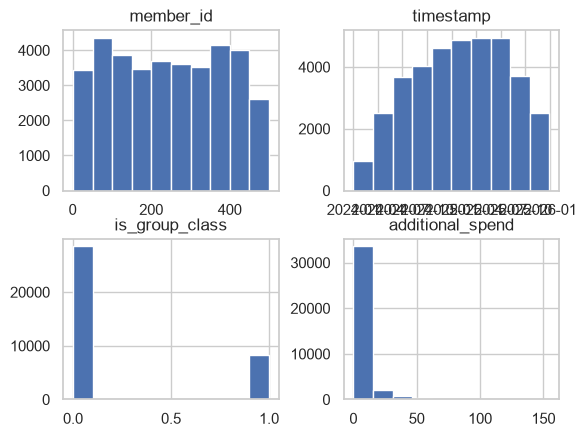

In [23]:
check_ins_df.hist()

In [24]:
from pathlib import Path

check_ins_test = check_ins_df.merge(contracts_df, on="member_id", how="left")
start_dt = pd.to_datetime(check_ins_test["start_date"])
end_dt = pd.to_datetime(check_ins_test["end_date"])

valid_hits = check_ins_test[(check_ins_test["timestamp"] >= start_dt) & (check_ins_test["timestamp"] < end_dt)]
assert len(valid_hits) == len(check_ins_df), "Check in outside of valid contract"
print(f"All check in take place within valid contract")

data_dir = Path("data/synthetic_raw")
data_dir.mkdir(parents=True, exist_ok=True)

raw_members_cols = ["member_id", "age", "distance_km", "promo_friends", "partners_company"]
members_df[raw_members_cols].to_csv(data_dir / "members.csv", index=False)
contracts_df.to_csv(data_dir / "contracts.csv", index=False)
check_ins_df.to_csv(data_dir / "check_ins.csv", index=False)

members_df.to_csv(data_dir / "ground_truth_members.csv", index=False)

print(f"Raw files and ground_truth saved into: {data_dir.resolve()}")

All check in take place within valid contract
Raw files and ground_truth saved into: C:\Users\milos\Desktop\Projects\gym-churn-project\notebooks\data\synthetic_raw
